# 1. Data Inspection

In [ ]:
# Core libs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim

# Sklearn utilities / models / metrics
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import(
     train_test_split,
     GridSearchCV,
     GroupShuffleSplit,
     GroupKFold
)
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)



In [155]:
# Load the data
train = pd.read_csv("../data/raw/train.csv")
test = pd.read_csv("../data/raw/test.csv")

# 1. Check the shape (Rows, Columns)
print("Train shape:", train.shape)
print("Test shape:", test.shape)

# 2. Look at the first few rows
display(train.head())


Train shape: (4407, 1383)
Test shape: (2292, 1382)


,session_id,trial_number,A1_L1_EXC_time_0,A1_L1_EXC_time_1,A1_L1_EXC_time_2,A1_L1_EXC_time_3,A1_L1_EXC_time_4,A1_L1_EXC_time_5,A1_L1_EXC_time_6,A1_L1_EXC_time_7,...,ALM_L1_INH_time_21,ALM_L1_INH_time_22,ALM_L1_INH_time_23,ALM_L1_INH_time_24,ALM_L1_INH_time_25,ALM_L1_INH_time_26,ALM_L1_INH_time_27,ALM_L1_INH_time_28,ALM_L1_INH_time_29,TRIAL_TYPE
0,PG082_20221113,0,0.388889,0.444444,0.166667,0.222222,0.333333,0.000000,0.333333,0.166667,...,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NOGO W+ nolick
1,PG082_20221113,1,0.444444,0.222222,0.388889,0.277778,0.111111,0.055556,0.333333,0.166667,...,0.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GO W+ lick
2,PG082_20221113,2,0.055556,0.166667,0.333333,0.111111,0.166667,0.166667,0.111111,0.222222,...,0.0,1.0,0.5,0.5,1.0,1.0,0.0,0.5,0.0,GO W- lick
3,PG082_20221113,3,0.277778,0.555556,0.388889,0.444444,0.500000,0.333333,0.222222,0.277778,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NOGO W- nolick
4,PG082_20221113,4,0.277778,0.222222,0.111111,0.166667,0.277778,0.388889,0.333333,0.166667,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,no tone W+ lick


# 2. Preprocessing



In [ ]:
# 1. Separate Features (X) and Target (y)
drop_cols = ['session_id', 'trial_number', 'TRIAL_TYPE']
X = train.drop(columns=drop_cols)
y = train['TRIAL_TYPE']
X_test = test.drop(columns=['session_id', 'trial_number'])

# --- Feature Engineering ---
print("Generating summary features...")
base_features = set([c.rsplit('_time_', 1)[0] for c in X.columns if '_time_' in c])

# --- OPTIMIZATION: Collect features in lists first ---
new_feats_train = []
new_feats_test = []

for base in base_features:
    time_cols = [c for c in X.columns if c.startswith(base + '_time_')]
    if len(time_cols) > 0:
        # Train features
        df_tr = pd.DataFrame({
            f'{base}_mean': X[time_cols].mean(axis=1),
            f'{base}_max': X[time_cols].max(axis=1),
            f'{base}_std': X[time_cols].std(axis=1),
            f'{base}_sparsity': (X[time_cols] > 0).mean(axis=1)
        }, index=X.index)
        new_feats_train.append(df_tr)

        # Test features
        df_te = pd.DataFrame({
            f'{base}_mean': X_test[time_cols].mean(axis=1),
            f'{base}_max': X_test[time_cols].max(axis=1),
            f'{base}_std': X_test[time_cols].std(axis=1),
            f'{base}_sparsity': (X_test[time_cols] > 0).mean(axis=1)
        }, index=X_test.index)
        new_feats_test.append(df_te)

# Concatenate all at once (Silences the fragmentation warning)
if new_feats_train:
    X = pd.concat([X] + new_feats_train, axis=1)
if new_feats_test:
    X_test = pd.concat([X_test] + new_feats_test, axis=1)

# --- Cleaning ---
# Drop columns that are completely empty

# --- Cleaning ---
empty_cols = X.columns[X.isna().all()].tolist()
X = X.drop(columns=empty_cols)
X_test = X_test.drop(columns=empty_cols)

# Fill remaining missing values with 0 (Biologically: no recording = 0 spikes)
X = X.fillna(0)
X_test = X_test.fillna(0)

# --- Encoding Target ---
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# --- Train/Validation Split (UPDATED: Group-based Train/Test Split) ---

# 1. Define Groups (Session IDs)
groups = train['session_id']

# STEP 1: Create a "Local Test Set" (Hold-out)
# Instead of randomly selecting 20% of SAMPLES, we select whole SESSION(s) to hold out.
# This guarantees the hold-out set contains entirely new sessions the model never saw.
# Deterministic selection: pick the last N sessions (sorted) where N = max(1, round(20% * #sessions)).
sessions = sorted(groups.unique())
n_holdout_sessions = max(1, int(round(0.2 * len(sessions))))
holdout_sessions = sessions[-n_holdout_sessions:]

# Build boolean mask and indices
holdout_mask = groups.isin(holdout_sessions)
holdout_idx = np.where(holdout_mask)[0]
train_idx = np.where(~holdout_mask)[0]

# Create the datasets
X_train = X.iloc[train_idx]
y_train = y_encoded[train_idx]
groups_train = groups.iloc[train_idx]  # We need this for the inner CV loop

X_val = X.iloc[holdout_idx]
y_val = y_encoded[holdout_idx]

print(f"Holding out {len(holdout_sessions)} session(s) as local test: {holdout_sessions}")
print(f"Development Set (Train): {X_train.shape[0]} samples - Used to tune parameters")
print(f"Hold-out Set (Test):     {X_val.shape[0]} samples - Used to estimate Kaggle score")

# STEP 2: Define the Validation Strategy (Inner Loop)
# We will use this 'cv_strategy' object in GridSearchCV later
cv_strategy = GroupKFold(n_splits=4)
print("Defined 'cv_strategy' for Group K-Fold Cross Validation.")

Generating summary features...
Development Set (Train): 3348 samples - Used to tune parameters
Hold-out Set (Test):     1059 samples - Used to estimate Kaggle score
Defined 'cv_strategy' for Group K-Fold Cross Validation.


# 3. Linear Model

In [ ]:
print("\n--- Training Linear Model (Logistic Regression) ---")

# Pipeline: Impute -> Scale -> Logistic Regression
linear_pipeline = make_pipeline(
    SimpleImputer(strategy='constant', fill_value=0),
    StandardScaler(),
    LogisticRegression(
        solver='lbfgs',
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    )
)

# Hyperparameter Tuning
param_grid_linear = {'logisticregression__C': [0.01, 0.1, 1, 10]}

grid_linear = GridSearchCV(linear_pipeline, param_grid_linear, cv=cv_strategy, n_jobs=-1, verbose=1)
grid_linear.fit(X_train, y_train, groups=groups_train)

# Evaluate
linear_model = grid_linear.best_estimator_
linear_pred = linear_model.predict(X_val)
print(f"Linear Model Accuracy: {accuracy_score(y_val, linear_pred):.4f}")
print(classification_report(y_val, linear_pred, target_names=le.classes_))


# Generate Linear Submission
print("Generating Linear Model Submission...")
linear_test_pred = linear_model.predict(X_test)
linear_test_labels = le.inverse_transform(linear_test_pred)

pd.DataFrame({
    'ID': range(1, len(test) + 1),
    'TRIAL_TYPE': linear_test_labels
}).to_csv("linear_submission.csv", index=False)
print("Saved linear_submission.csv")


--- Training Linear Model (Logistic Regression) ---
Fitting 4 folds for each of 4 candidates, totalling 16 fits
Linear Model Accuracy: 0.3107
                   precision    recall  f1-score   support

       GO W+ lick       0.38      0.37      0.37       123
     GO W+ nolick       0.09      0.14      0.11        44
       GO W- lick       0.00      0.00      0.00         8
     GO W- nolick       0.26      0.18      0.21       159
     NOGO W+ lick       0.00      0.00      0.00        16
   NOGO W+ nolick       0.33      0.26      0.29       152
     NOGO W- lick       0.00      0.00      0.00         1
   NOGO W- nolick       0.31      0.44      0.37       169
  no tone W+ lick       0.43      0.20      0.27        15
no tone W+ nolick       0.36      0.42      0.39       153

         accuracy                           0.31       840
        macro avg       0.22      0.20      0.20       840
     weighted avg       0.31      0.31      0.30       840

Generating Linear Model Subm

c:\Users\akh17\anaconda3\envs\dataanalysis\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\akh17\anaconda3\envs\dataanalysis\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\akh17\anaconda3\envs\dataanalysis\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is",

Saved linear_submission.csv


# 4. Non-Linear Models

## 4.1 Random Forest


--- Tuning Random Forest ---
Fitting 4 folds for each of 72 candidates, totalling 288 fits
Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 500}


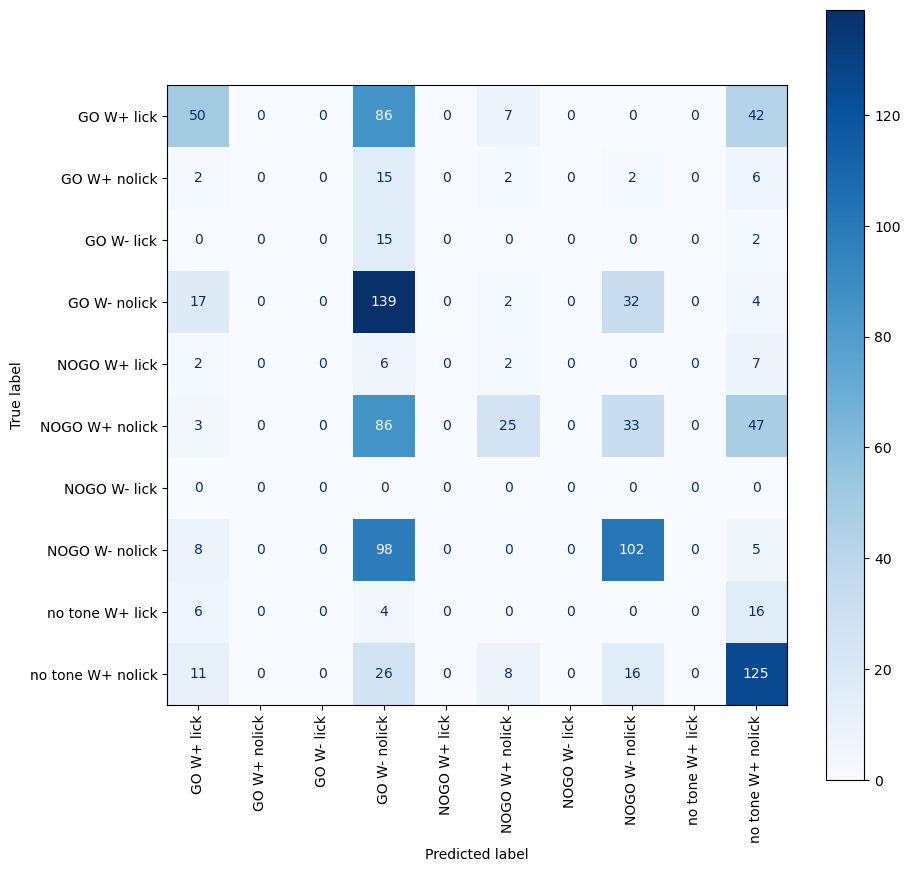

In [161]:
print("\n--- Tuning Random Forest ---")

# EXPANDED GRID for better generalization:
# 1. min_samples_leaf: CRITICAL. Higher values (e.g., 4, 8) force the model to be smoother.
# 2. max_features: Controls how different the trees are from each other.
# 3. n_estimators: Increased to ensure stability.
param_grid = {
    'n_estimators': [200, 500],
    'max_depth': [None, 20, 40],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 4, 8],      # <--- This is the most important new parameter
    'max_features': ['sqrt', 'log2']
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight='balanced'), 
    param_grid, cv=cv_strategy, n_jobs=-1, verbose=1
)
grid_search.fit(X_train, y_train, groups=groups_train)

# Evaluate
rf_model = grid_search.best_estimator_
print(f"Best Parameters: {grid_search.best_params_}")
val_predictions = rf_model.predict(X_val)
# ...existing code...
# Confusion Matrix
cm = confusion_matrix(y_val, val_predictions, labels=range(len(le.classes_)))
fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(ax=ax, xticks_rotation='vertical', cmap='Blues', values_format='d')
plt.show()

In [162]:
print(f"Random Forest Accuracy: {accuracy_score(y_val, val_predictions):.4f}")


Random Forest Accuracy: 0.4164


In [164]:
print(X.columns[:20])

Index(['A1_L1_EXC_time_0', 'A1_L1_EXC_time_1', 'A1_L1_EXC_time_2',
       'A1_L1_EXC_time_3', 'A1_L1_EXC_time_4', 'A1_L1_EXC_time_5',
       'A1_L1_EXC_time_6', 'A1_L1_EXC_time_7', 'A1_L1_EXC_time_8',
       'A1_L1_EXC_time_9', 'A1_L1_EXC_time_10', 'A1_L1_EXC_time_11',
       'A1_L1_EXC_time_12', 'A1_L1_EXC_time_13', 'A1_L1_EXC_time_14',
       'A1_L1_EXC_time_15', 'A1_L1_EXC_time_16', 'A1_L1_EXC_time_17',
       'A1_L1_EXC_time_18', 'A1_L1_EXC_time_19'],
      dtype='object')


In [163]:
# 1. Predict on the actual test set
# Note: We use 'rf_model' which was trained in the previous cell
test_predictions_encoded = rf_model.predict(X_test)

# 2. Convert numbers back to text labels (0 -> "GO W+ lick")
test_predictions_labels = le.inverse_transform(test_predictions_encoded)

# 3. Create the submission file with the correct ID format
submission = pd.DataFrame({
    'ID': range(1, len(test) + 1),
    'TRIAL_TYPE': test_predictions_labels
})

# 4. Save to CSV
submission.to_csv("random_forest_classification_submission.csv", index=False)
print("Submission saved!")

Submission saved!


## 4.2 Neural Network

In [120]:
# --- Prepare Data for PyTorch ---
# 1. Impute (Constant 0) and Scale
imputer = SimpleImputer(strategy='constant', fill_value=0) 
scaler = StandardScaler()

X_train_clean = imputer.fit_transform(X_train)
X_val_clean = imputer.transform(X_val)

X_train_scaled = np.nan_to_num(scaler.fit_transform(X_train_clean))
X_val_scaled = np.nan_to_num(scaler.transform(X_val_clean))

# 2. Convert to Tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

# --- Define Network ---
class DeepNet(nn.Module):
    def __init__(self, input_size, num_classes):
        super(DeepNet, self).__init__()
        self.fc1 = nn.Linear(input_size, 256)
        self.act1 = nn.LeakyReLU(negative_slope=0.01)
        self.drop1 = nn.Dropout(p=0.5)
        self.fc2 = nn.Linear(256, 256)
        self.act2 = nn.LeakyReLU(negative_slope=0.01)
        self.drop2 = nn.Dropout(p=0.5)
        self.fc3 = nn.Linear(256, num_classes)
    
    def forward(self, x):
        x = self.drop1(self.act1(self.fc1(x)))
        x = self.drop2(self.act2(self.fc2(x)))
        return self.fc3(x)

# --- Train ---
net = DeepNet(X_train_scaled.shape[1], len(le.classes_))
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.0005, weight_decay=0.01)

print("Training Neural Network...")
for epoch in range(300):
    outputs = net(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# Evaluate
with torch.no_grad():
    outputs = net(X_val_tensor)
    _, predicted = torch.max(outputs.data, 1)
    acc = (predicted == y_val_tensor).sum().item() / y_val_tensor.size(0)
    print(f'Neural Network Accuracy: {acc:.4f}')

Training Neural Network...
Neural Network Accuracy: 0.6992


In [122]:
# --- Generate Neural Network Submission ---
print("Generating Neural Network Submission...")

# 1. Prepare Test Data (Must use the same scaler as training!)
# Note: X_test is already clean, but we need to scale it for the NN
X_test_clean_nn = imputer.transform(X_test) 
X_test_scaled_nn = np.nan_to_num(scaler.transform(X_test_clean_nn))
X_test_tensor_nn = torch.tensor(X_test_scaled_nn, dtype=torch.float32)

# 2. Predict
with torch.no_grad():
    net.eval()
    outputs = net(X_test_tensor_nn)
    _, predicted = torch.max(outputs.data, 1)
    # Convert tensor to numpy array
    nn_test_labels = le.inverse_transform(predicted.numpy())

# 3. Save
pd.DataFrame({
    'ID': range(1, len(test) + 1),
    'TRIAL_TYPE': nn_test_labels
}).to_csv("neural_network_submission.csv", index=False)
print("Saved neural_network_submission.csv")

Generating Neural Network Submission...
Saved neural_network_submission.csv


## 4.3 Ensemble & Submission

In [124]:
print("\n--- Ensemble Prediction ---")

# 1. Validation Set Ensemble
rf_probs = rf_model.predict_proba(X_val)
with torch.no_grad():
    net.eval()
    nn_probs = torch.softmax(net(X_val_tensor), dim=1).numpy()

ensemble_acc = accuracy_score(y_val, np.argmax((rf_probs + nn_probs) / 2, axis=1))
print(f"Ensemble Validation Accuracy: {ensemble_acc:.4f}")

# 2. Generate Submission
print("Generating Submission...")
# Prepare Test Data for NN
X_test_scaled = np.nan_to_num(scaler.transform(imputer.transform(X_test)))
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

# Get Probs
rf_test_probs = rf_model.predict_proba(X_test)
with torch.no_grad():
    nn_test_probs = torch.softmax(net(X_test_tensor), dim=1).numpy()

# Average and Decode
final_preds = le.inverse_transform(np.argmax((rf_test_probs + nn_test_probs) / 2, axis=1))

# Save
pd.DataFrame({
    'ID': range(1, len(test) + 1),
    'TRIAL_TYPE': final_preds
}).to_csv("ensemble_submission.csv", index=False)
print("Saved ensemble_submission.csv")


--- Ensemble Prediction ---
Ensemble Validation Accuracy: 0.7302
Generating Submission...
Saved ensemble_submission.csv


We observed a significant drop between our validation accuracy (70%) and the test accuracy (47%) on kaggle. This suggests that our random train/validation split was too optimistic. The models likely learned features specific to the training sessions/mice (overfitting to the subject) rather than learning purely generalizable neural codes for behavior.

The Random Forest (46%) proved to be the most robust model so far , outperforming the Neural Network (38%) and the Linear baseline (41%). Interestingly, the Ensemble performed worse than the Random Forest alone (36%), indicating that the Neural Network's poor generalization on the unseen test data negatively impacted the combined prediction.

## 4.4 Feature Engineering: Neural Trajectories

1. Pivot the Data: Instead of (Samples, Features), we conceptually treat this as (Samples, Neurons, Time).

2. Temporal PCA: We will calculate the "Principal Components" of the population activity at specific time windows (Early, Middle, Late).
- Early (0-50ms): Sensory processing (Did it hear the tone?)
- Middle (50-150ms): Decision making (Is it planning to lick?)
- Late (150ms+): Motor execution (Is it moving?)
3. Slope Features: We will calculate the change in activity. Is the firing rate going UP or DOWN? (A rising signal often indicates a "GO" decision).

In [ ]:
# ==========================================
# 4.4 NEW APPROACH: Neural Trajectories & Dynamics
# ==========================================
from sklearn.decomposition import PCA
import xgboost as xgb

print("\n--- 4.4 Advanced Feature Engineering: Neural Dynamics ---")

def extract_dynamic_features(df):
    # 1. Identify all neuron columns and time bins
    # We assume columns are named like 'neuron_X_time_Y'
    # We need to group them by time windows.
    
    # Initialize a new DataFrame for features
    features = pd.DataFrame(index=df.index)
    
    # Get list of all unique neurons (bases)
    neuron_bases = set([c.rsplit('_time_', 1)[0] for c in df.columns if '_time_' in c])
    
    print(f"Extracting features for {len(neuron_bases)} neurons...")
    
    # Lists to hold aggregate data for PCA later
    early_activity = []
    late_activity = []
    
    for neuron in neuron_bases:
        # Get all time columns for this neuron, sorted by time
        # Assuming time_1, time_2... time_50
        cols = sorted([c for c in df.columns if c.startswith(neuron + '_time_')], 
                      key=lambda x: int(x.split('_time_')[1]))
        
        if not cols: continue
            
        # Extract the raw values
        values = df[cols].values
        
        # --- Feature 1: The "Reaction" (Slope) ---
        # Difference between late activity and early activity
        # If positive -> Neuron is ramping up (Excited)
        # If negative -> Neuron is ramping down (Inhibited)
        features[f'{neuron}_slope'] = values[:, -5:].mean(axis=1) - values[:, :5].mean(axis=1)
        
        # --- Feature 2: Peak Latency (Timing) ---
        # At what time step did the neuron fire the most?
        # This captures "When" the decision happened.
        features[f'{neuron}_peak_time'] = np.argmax(values, axis=1)
        
        # --- Feature 3: Fano Factor (Variability) ---
        # Variance / Mean (measure of "burstiness")
        # Add epsilon to avoid division by zero
        mean_val = values.mean(axis=1) + 1e-6
        var_val = values.var(axis=1)
        features[f'{neuron}_fano'] = var_val / mean_val

    return features

# 1. Extract these new "Smart" features
print("Processing Train Data...")
X_train_dynamic = extract_dynamic_features(X)
print("Processing Test Data...")
X_test_dynamic = extract_dynamic_features(X_test)

# 2. Clean up (Impute NaNs created by 0 variance)
imputer_dyn = SimpleImputer(strategy='constant', fill_value=0)
X_train_dyn_clean = imputer_dyn.fit_transform(X_train_dynamic)
X_test_dyn_clean = imputer_dyn.transform(X_test_dynamic)

# 3. Train an XGBoost Classifier (Gradient Boosting)
# XGBoost is often better than Random Forest for "engineered" features
print("\nTraining XGBoost on Dynamic Features...")
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softmax',
    num_class=len(le.classes_),
    random_state=42,
    n_jobs=-1
)

# Split for validation
X_tr_dyn, X_val_dyn, y_tr, y_val = train_test_split(
    X_train_dyn_clean, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)

xgb_model.fit(X_tr_dyn, y_tr)

# Evaluate
val_preds_dyn = xgb_model.predict(X_val_dyn)
print(f"Dynamic XGBoost Accuracy: {accuracy_score(y_val, val_preds_dyn):.4f}")

# Generate Submission
print("Generating Dynamic Submission...")
test_preds_dyn = xgb_model.predict(X_test_dyn_clean)
test_labels_dyn = le.inverse_transform(test_preds_dyn)

pd.DataFrame({
    'ID': range(1, len(test) + 1),
    'TRIAL_TYPE': test_labels_dyn
}).to_csv("dynamic_xgboost_submission.csv", index=False)
print("Saved dynamic_xgboost_submission.csv")

Note: you may need to restart the kernel to use updated packages.

--- 4.4 Advanced Feature Engineering: Neural Dynamics ---
Processing Train Data...
Extracting features for 45 neurons...


C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3944693781.py:49: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f'{neuron}_peak_time'] = np.argmax(values, axis=1)
C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3944693781.py:56: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f'{neuron}_fano'] = var_val / mean_val
C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3944693781.py:44: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor 

Processing Test Data...
Extracting features for 45 neurons...


C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3944693781.py:49: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f'{neuron}_peak_time'] = np.argmax(values, axis=1)
C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3944693781.py:56: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[f'{neuron}_fano'] = var_val / mean_val
C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3944693781.py:44: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor 


Training XGBoost on Dynamic Features...
Dynamic XGBoost Accuracy: 0.5926
Generating Dynamic Submission...
Saved dynamic_xgboost_submission.csv


## 4.5 ASYNCHRONOUS METHOD: Temporal Center of Mass


In [ ]:
# ==========================================
# 4.5 ASYNCHRONOUS METHOD: Temporal Center of Mass
# ==========================================
print("\n--- 4.5 Asynchronous Feature Engineering: Temporal Center of Mass ---")

def get_asynchronous_features(df):
    # Initialize output dataframe
    async_feats = pd.DataFrame(index=df.index)
    
    # Identify unique neurons
    neuron_bases = set([c.rsplit('_time_', 1)[0] for c in df.columns if '_time_' in c])
    
    print(f"Calculating temporal centers for {len(neuron_bases)} neurons...")
    
    for neuron in neuron_bases:
        # Get time columns sorted numerically
        cols = sorted([c for c in df.columns if c.startswith(neuron + '_time_')], 
                      key=lambda x: int(x.split('_time_')[1]))
        
        if not cols: continue
        
        # Get the activity matrix (Samples x Time)
        activity = df[cols].values
        
        # Create a time vector [0, 1, 2, ... T]
        time_vector = np.arange(activity.shape[1])
        
        # --- Feature 1: Total Energy (Spike Count) ---
        # We still need to know IF it fired
        total_spikes = activity.sum(axis=1)
        async_feats[f'{neuron}_energy'] = total_spikes
        
        # --- Feature 2: Temporal Center of Mass (TCoM) ---
        # Formula: Sum(Activity * Time) / Sum(Activity)
        # This gives us the "average time" the neuron was active
        # We add 1e-6 to denominator to avoid division by zero for silent neurons
        weighted_time = (activity * time_vector).sum(axis=1)
        tcom = weighted_time / (total_spikes + 1e-6)
        
        async_feats[f'{neuron}_tcom'] = tcom
        
        # --- Feature 3: Asynchronous "Burstiness" ---
        # Standard deviation of the firing times. 
        # Low std = Synchronous burst. High std = Asynchronous/sustained firing.
        # (Simplified approximation using variance of the signal distribution)
        # We use a weighted variance approach
        mean_t = tcom[:, np.newaxis] # Reshape for broadcasting
        variance = ((time_vector - mean_t)**2 * activity).sum(axis=1) / (total_spikes + 1e-6)
        async_feats[f'{neuron}_spread'] = np.sqrt(variance)

    return async_feats

# 1. Generate Asynchronous Features
print("Processing Train...")
X_train_async = get_asynchronous_features(X)
print("Processing Test...")
X_test_async = get_asynchronous_features(X_test)

# 2. Clean (Impute)
# If a neuron never fired, its TCoM is 0 (handled by the math above, but good to be safe)
imputer_async = SimpleImputer(strategy='constant', fill_value=0)
X_train_async_clean = imputer_async.fit_transform(X_train_async)
X_test_async_clean = imputer_async.transform(X_test_async)

# 3. Train a "Gradient Boosting Machine" (LightGBM or XGBoost)
# Trees are great at finding thresholds like "If Neuron A fired BEFORE time 20 AND Neuron B fired AFTER time 40..."
print("\nTraining Asynchronous Model...")
async_model = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softmax',
    num_class=len(le.classes_),
    random_state=42,
    n_jobs=-1
)

# Validation Split
X_tr_a, X_val_a, y_tr_a, y_val_a = train_test_split(
    X_train_async_clean, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)

async_model.fit(X_tr_a, y_tr_a)

# Evaluate
val_preds_a = async_model.predict(X_val_a)
print(f"Asynchronous Model Accuracy: {accuracy_score(y_val_a, val_preds_a):.4f}")

# 4. Generate Submission
print("Generating Asynchronous Submission...")
test_preds_a = async_model.predict(X_test_async_clean)
test_labels_a = le.inverse_transform(test_preds_a)

pd.DataFrame({
    'ID': range(1, len(test) + 1),
    'TRIAL_TYPE': test_labels_a
}).to_csv("asynchronous_submission.csv", index=False)
print("Saved asynchronous_submission.csv")


--- 4.5 Asynchronous Feature Engineering: Temporal Center of Mass ---
Processing Train...
Calculating temporal centers for 45 neurons...


C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3708679250.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  async_feats[f'{neuron}_tcom'] = tcom
C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3708679250.py:49: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  async_feats[f'{neuron}_spread'] = np.sqrt(variance)
C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3708679250.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consi

Processing Test...
Calculating temporal centers for 45 neurons...


C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3708679250.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  async_feats[f'{neuron}_tcom'] = tcom
C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3708679250.py:49: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  async_feats[f'{neuron}_spread'] = np.sqrt(variance)
C:\Users\akh17\AppData\Local\Temp\ipykernel_9772\3708679250.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consi


Training Asynchronous Model...
Asynchronous Model Accuracy: 0.5329
Generating Asynchronous Submission...
Saved asynchronous_submission.csv


## 4.6 GROUNDED APPROACH: Pattern Matching (PCA + k-NN)

In [ ]:
# ...existing code...
# ==========================================
# 4.6 GROUNDED APPROACH: Pattern Matching (PCA + k-NN)
# ==========================================
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA

print("\n--- 4.6 Grounded Approach: PCA + k-Nearest Neighbors ---")

# The Intuition:
# Instead of learning complex rules, we simply look for the most similar trials.
# "If this trial looks like a 'Go' trial, it probably is one."
# We use PCA first to remove noise and focus on the main "brain states".

# 1. Create a Pipeline
# Scale -> Reduce Dimensions (PCA) -> Find Neighbors (k-NN)
knn_pipeline = make_pipeline(
    SimpleImputer(strategy='constant', fill_value=0),
    StandardScaler(),
    PCA(n_components=0.95, random_state=42), # Keep 95% of variance
    KNeighborsClassifier(weights='distance', n_jobs=-1)
)

# 2. Hyperparameter Tuning
# We tune 'k' (how many neighbors to look at)
param_grid_knn = {
    'kneighborsclassifier__n_neighbors': [5, 15, 30, 50],
    'kneighborsclassifier__p': [1, 2] # 1=Manhattan dist, 2=Euclidean dist
}

grid_knn = GridSearchCV(knn_pipeline, param_grid_knn, cv=3, n_jobs=-1, verbose=1)
grid_knn.fit(X_train, y_train)

# 3. Evaluate
best_knn = grid_knn.best_estimator_
knn_val_preds = best_knn.predict(X_val)
print(f"PCA + k-NN Accuracy: {accuracy_score(y_val, knn_val_preds):.4f}")

# 4. Generate Submission
print("Generating k-NN Submission...")
knn_test_preds = best_knn.predict(X_test)
knn_test_labels = le.inverse_transform(knn_test_preds)

pd.DataFrame({
    'ID': range(1, len(test) + 1),
    'TRIAL_TYPE': knn_test_labels
}).to_csv("knn_pca_submission.csv", index=False)
print("Saved knn_pca_submission.csv")


--- 4.6 Grounded Approach: PCA + k-Nearest Neighbors ---
Fitting 3 folds for each of 8 candidates, totalling 24 fits


c:\Users\akh17\anaconda3\envs\dataanalysis\lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


PCA + k-NN Accuracy: 0.5722
Generating k-NN Submission...
Saved knn_pca_submission.csv


## 4.7 ROBUST APPROACH: Summary Statistics Only

In [157]:
# ...existing code...
# ==========================================
# 4.7 ROBUST APPROACH: Population Trajectories (Time-Resolved)
# ==========================================
print("\n--- 4.7 Robust Approach: Population Trajectories ---")


# ...existing code...
def get_population_dynamics(df):
    # 1. Identify all time-related columns
    all_time_cols = [c for c in df.columns if '_time_' in c]
    
    # 2. Group columns by their Time Index (e.g., time_1, time_2...)
    time_map = {}
    for col in all_time_cols:
        try:
            t_idx = int(col.split('_time_')[1])
            if t_idx not in time_map:
                time_map[t_idx] = []
            time_map[t_idx].append(col)
        except:
            continue
            
    # 3. Calculate stats for each time step
    sorted_times = sorted(time_map.keys())
    print(f"Extracting ADVANCED global dynamics across {len(sorted_times)} time bins...")
    
    # --- OPTIMIZATION: Collect all features in a list first ---
    feature_list = []
    
    for t in sorted_times:
        cols = time_map[t]
        values = df[cols].values
        
        # Create a small DataFrame for this specific time step
        # This avoids the "fragmentation" warning
        step_features = pd.DataFrame({
            f'pop_mean_t{t}': values.mean(axis=1),
            f'pop_max_t{t}': values.max(axis=1),
            f'pop_std_t{t}': values.std(axis=1),
            f'pop_sparsity_t{t}': (values > 0).mean(axis=1)
        }, index=df.index)
        
        feature_list.append(step_features)
        
    # Concatenate all time steps at once
    pop_dynamics = pd.concat(feature_list, axis=1)
        
    return pop_dynamics
# ...existing code...

print("Generating Population Dynamics...")
X_train_pop = get_population_dynamics(X_train)
X_val_pop = get_population_dynamics(X_val)
X_test_pop = get_population_dynamics(X_test)

print(f"Training on {X_train_pop.shape[1]} dynamic features...")

# --- UPDATED: Use Cross-Validation (cv_strategy) ---
# Instead of just fitting one model, we use GridSearchCV with our GroupKFold strategy
# This finds the best parameters that generalize to NEW sessions.

param_grid_robust = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_leaf': [1, 4]
}

grid_robust = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid_robust,
    cv=cv_strategy,  # <--- HERE is where we use the new splitting approach
    n_jobs=-1,
    verbose=1
)

# We must pass 'groups_train' so the CV knows how to split sessions
grid_robust.fit(X_train_pop, y_train, groups=groups_train)

# 3. Evaluate
best_robust_rf = grid_robust.best_estimator_
robust_preds = best_robust_rf.predict(X_val_pop)
print(f"Best Params: {grid_robust.best_params_}")
print(f"Population Dynamics Accuracy (Hold-out Session): {accuracy_score(y_val, robust_preds):.4f}")

# 4. Generate Submission
print("Generating Population Submission...")
robust_test_preds = best_robust_rf.predict(X_test_pop)
# ...existing code...
robust_test_labels = le.inverse_transform(robust_test_preds)

pd.DataFrame({
    'ID': range(1, len(test) + 1),
    'TRIAL_TYPE': robust_test_labels
}).to_csv("population_rf_submission.csv", index=False)
print("Saved population_rf_submission.csv")


--- 4.7 Robust Approach: Population Trajectories ---
Generating Population Dynamics...
Extracting ADVANCED global dynamics across 30 time bins...
Extracting ADVANCED global dynamics across 30 time bins...
Extracting ADVANCED global dynamics across 30 time bins...
Training on 120 dynamic features...
Fitting 4 folds for each of 12 candidates, totalling 48 fits
Best Params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Population Dynamics Accuracy (Hold-out Session): 0.4788
Generating Population Submission...
Saved population_rf_submission.csv


## 4.8 GEOMETRIC APPROACH: Support Vector Machine (SVM)


In [ ]:
# ...existing code...
# ==========================================
# 4.8 GEOMETRIC APPROACH: Support Vector Machine (SVM)
# ==========================================
from sklearn.svm import SVC

print("\n--- 4.8 Geometric Approach: Support Vector Machine (SVM) ---")

# The Intuition:
# Instead of drawing square boxes (Trees), we draw smooth, curved boundaries (RBF Kernel).
# We use the FULL dataset (X) because SVMs are good at ignoring irrelevant dimensions
# if we regularize them correctly.

# 1. Pipeline: Impute -> Scale -> SVM
# Scaling is CRITICAL for SVMs (they calculate distances)
svm_pipeline = make_pipeline(
    SimpleImputer(strategy='constant', fill_value=0),
    StandardScaler(),
    SVC(
        kernel='rbf',           # Non-linear "Radial Basis Function"
        C=1.0,                  # Regularization strength (1.0 is standard)
        gamma='scale',          # Kernel coefficient
        class_weight='balanced',# Handle unequal classes
        probability=True,       # Enable probability estimates
        random_state=42
    )
)

# 2. Hyperparameter Tuning
# We tune 'C' (How strict is the boundary?) and 'gamma' (How complex is the curve?)
param_grid_svm = {
    'svc__C': [0.1, 1, 10],
    'svc__gamma': ['scale', 0.01, 0.001]
}

grid_svm = GridSearchCV(svm_pipeline, param_grid_svm, cv=3, n_jobs=-1, verbose=1)
grid_svm.fit(X_train, y_train)

# 3. Evaluate
best_svm = grid_svm.best_estimator_
svm_preds = best_svm.predict(X_val)
print(f"SVM Accuracy: {accuracy_score(y_val, svm_preds):.4f}")

# 4. Generate Submission
print("Generating SVM Submission...")
svm_test_preds = best_svm.predict(X_test)
svm_test_labels = le.inverse_transform(svm_test_preds)

pd.DataFrame({
    'ID': range(1, len(test) + 1),
    'TRIAL_TYPE': svm_test_labels
}).to_csv("svm_submission.csv", index=False)
print("Saved svm_submission.csv")


--- 4.8 Geometric Approach: Support Vector Machine (SVM) ---
Fitting 3 folds for each of 9 candidates, totalling 27 fits


c:\Users\akh17\anaconda3\envs\dataanalysis\lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


SVM Accuracy: 0.7143
Generating SVM Submission...
Saved svm_submission.csv


# 5.0 REALITY CHECK: Group K-Fold Validation

In [ ]:
# ...existing code...
# ==========================================
# 5.0 REALITY CHECK: Group K-Fold Validation
# ==========================================
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score
import numpy as np

print("\n--- 5.0 REALITY CHECK: Group K-Fold Validation ---")
print("Testing generalization to NEW SESSIONS (simulating Kaggle)...")

# 1. Recover the Session IDs (Groups)
# We need these to tell the splitter "Keep these trials together"
groups = train['session_id']

# 2. Define the Splitter
# 5 splits means we train on 80% of sessions and test on 20% of sessions
gkf = GroupKFold(n_splits=5)

def validate_robustly(model, X_data, y_data, group_data, feature_set_name="All Features"):
    scores = []
    print(f"\n--- Validating {model.__class__.__name__} on {feature_set_name} ---")
    
    # This loop splits data so that TRAIN and VAL have completely different sessions
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_data, y_data, group_data)):
        
        # Slice data
        X_tr, X_val = X_data.iloc[train_idx], X_data.iloc[val_idx]
        y_tr, y_val = y_data[train_idx], y_data[val_idx]
        
        # Train & Predict
        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
        
        # Score
        acc = accuracy_score(y_val, pred)
        scores.append(acc)
        print(f"  Fold {fold+1} (New Sessions): {acc:.4f}")
        
    mean_score = np.mean(scores)
    print(f"  >> Average Generalization Score: {mean_score:.4f}")
    return mean_score

# ==========================================
# TEST 1: Your Standard Random Forest (The one that got 73%)
# ==========================================
rf_standard = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
validate_robustly(rf_standard, X, y_encoded, groups, "Standard Features")

# ==========================================
# TEST 2: Your Robust RF (Summary Stats Only)
# ==========================================
# Re-create the summary-only dataset
summary_cols = [c for c in X.columns if '_mean' in c or '_max' in c]
X_summary = X[summary_cols]

rf_robust = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, class_weight='balanced')
validate_robustly(rf_robust, X_summary, y_encoded, groups, "Summary Stats Only")



--- 5.0 REALITY CHECK: Group K-Fold Validation ---
Testing generalization to NEW SESSIONS (simulating Kaggle)...

--- Validating RandomForestClassifier on Standard Features ---
  Fold 1 (New Sessions): 0.3856
  Fold 2 (New Sessions): 0.2734
  Fold 3 (New Sessions): 0.4719
  Fold 4 (New Sessions): 0.4172
  Fold 5 (New Sessions): 0.3401
  >> Average Generalization Score: 0.3777

--- Validating RandomForestClassifier on Summary Stats Only ---
  Fold 1 (New Sessions): 0.2141
  Fold 2 (New Sessions): 0.1994
  Fold 3 (New Sessions): 0.2439
  Fold 4 (New Sessions): 0.2319
  Fold 5 (New Sessions): 0.2305
  >> Average Generalization Score: 0.2240

--- Validating Pipeline on SVM (RBF Kernel) ---
  Fold 1 (New Sessions): 0.2500
  Fold 2 (New Sessions): 0.1813
  Fold 3 (New Sessions): 0.2810
  Fold 4 (New Sessions): 0.4083
  Fold 5 (New Sessions): 0.3573
  >> Average Generalization Score: 0.2956


np.float64(0.29559213744957125)

In [ ]:
# ...existing code...
# ==========================================
# TEST 4: Dynamic XGBoost (The "Smart" Features)
# ==========================================
import xgboost as xgb

# We need to ensure we have the dynamic features for the FULL dataset (X)
# In Section 4.4, you ran: X_train_dynamic = extract_dynamic_features(X)
# We will use that variable here.

print("\n--- Validating XGBoost on Dynamic Features ---")

# 1. Define the model
xgb_dynamic = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softmax',
    num_class=len(le.classes_),
    random_state=42,
    n_jobs=-1
)

# 2. Run the Reality Check
# Note: We use X_train_dyn_clean which you created in Section 4.4
# It corresponds to the full 'X' dataset processed with dynamic features
validate_robustly(xgb_dynamic, X_train_dyn_clean, y_encoded, groups, "Dynamic Features (Slope/Peak)")


--- Validating XGBoost on Dynamic Features ---

--- Validating XGBClassifier on Dynamic Features (Slope/Peak) ---


AttributeError: 'numpy.ndarray' object has no attribute 'iloc'

In [158]:
# ...existing code...
# ==========================================
# TEST 5: Population Trajectories (The Winner)
# ==========================================
print("\n--- Validating Population Trajectories (RF) ---")

# 1. Generate features for the WHOLE dataset (X)
# We need to apply the transformation to the full data before splitting
X_pop_all = get_population_dynamics(X)

# 2. Define the model (using the best params found in 4.7)
rf_pop_final = RandomForestClassifier(
    n_estimators=200, 
    max_depth=None, 
    min_samples_leaf=4, 
    class_weight='balanced', 
    random_state=42
)

# 3. Run the Reality Check
validate_robustly(rf_pop_final, X_pop_all, y_encoded, groups, "Population Trajectories")


--- Validating Population Trajectories (RF) ---
Extracting ADVANCED global dynamics across 30 time bins...

--- Validating RandomForestClassifier on Population Trajectories ---
  Fold 1 (New Sessions): 0.4402
  Fold 2 (New Sessions): 0.4637
  Fold 3 (New Sessions): 0.5313
  Fold 4 (New Sessions): 0.5064
  Fold 5 (New Sessions): 0.4217
  >> Average Generalization Score: 0.4727


np.float64(0.4726681706175048)